# Подбор параметров поиска



В блокноте подбираются параметры поиска по регламенту АССБ. Содержание блокнота:

1. нарезка корпуса на чанки;
2. сравнение BM25 и векторного поиска по отдельности;
3. гибрид двух методов и вес α;
4. число кандидатов для переранжирования;
5. раскрытие аббревиатур;
6. итоговое сравнение всех методов с выбранными параметрами.

**Как оценивается поиск.** Тестовый набор `data/queries.jsonl` содержит 76 вопросов: 73 с ответом в корпусе и 3 вопроса-ловушки (Л1–Л3), ответа на которые в регламенте нет. Для каждого вопроса с ответом размечены фразы-доказательства, то есть точные цитаты из документов. Найденный чанк считается правильным, если в нём есть такая фраза. Благодаря этому метрики считаются автоматически, без ручной проверки и без LLM.

- **Recall@5** — доля вопросов, у которых правильный чанк попал в первые 5 результатов. Один вопрос — это 1/73 ≈ 0.014.
- **MRR@10** — среднее по вопросам значение 1 / (место первого правильного чанка). Метрика показывает, насколько высоко стоит ответ.
- **Ловушки** — доля ловушек, у которых лучший чанк получил оценку ниже, чем у любого вопроса с ответом.



In [1]:
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.chunk_quality import VARIANTS, assess
from src.chunking import CORPUS_DIR, MAX_CHARS, OVERLAP_CHARS, chunk_corpus
from src.evaluate import CATEGORIES, evaluate, load_queries
from src.hybrid_retrieval import DEFAULT_ALPHA, RERANK_DEPTH, HybridRetriever, RerankedRetriever, make_reranker
from src.retrieval import AbbreviationExpander, BM25Retriever, dense_retriever, load_chunks, load_glossary, make_encoder

In [2]:
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "lines.linewidth": 2,
    "lines.markersize": 6,
    "font.size": 10,
})
pd.set_option("display.precision", 3)


def two_panels(title):
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
    fig.suptitle(title, x=0.01, ha="left", fontsize=12)
    return fig, axes


def heatmap(ax, table, vmin, fmt="{:.2f}"):
    values = table.values.astype(float)
    image = ax.imshow(values, cmap="Blues", vmin=vmin, vmax=1.0, aspect="auto")
    ax.set_xticks(range(table.shape[1]), table.columns, rotation=20, ha="right")
    ax.set_yticks(range(table.shape[0]), table.index)
    for i in range(table.shape[0]):
        for j in range(table.shape[1]):
            v = values[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9,
                    color="white" if v > vmin + 0.7 * (1 - vmin) else "#0b0b0b")
    ax.grid(False)
    return image

In [3]:
queries = load_queries()
encoder = make_encoder("e5")
cross_encoder = make_reranker()
rerank_cache = {}
n_answerable = sum(bool(q["evidence"]) for q in queries)
print(f"запросов: {len(queries)}, с ответом: {n_answerable}, ловушек: {len(queries) - n_answerable}")


def metrics(retriever, expand=False):
    """Recall@5, MRR@10, ловушки и метрики по группам вопросов для одного метода поиска."""
    r = evaluate(retriever, queries, expand)
    row = {"Recall@5": r["recall@5"], "MRR@10": r["mrr"], "Ловушки": r["traps"]}
    for category, label in CATEGORIES.items():
        row[label] = r["by_category"][category]["mrr"]
    row["С1–С5, Recall@5"] = r["synonyms"]["recall@5"]
    row["С1–С5, MRR@10"] = r["synonyms"]["mrr"]
    return row


def reranked(base, depth=RERANK_DEPTH):
    return RerankedRetriever(base, cross_encoder, depth=depth, cache=rerank_cache)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

запросов: 76, с ответом: 73, ловушек: 3


## 1. Нарезка корпуса
Для различных методов поиска, не требующих дополнительных настроек параметров, подбирается оптимальная нарезка корпуса на чанки.
 Корпус нарезается шестью способами (максимальная длина чанка `max_chars` и перекрытие `overlap` в символах), и на каждом варианте запускаются BM25, векторный поиск e5 и гибрид RRF.

In [4]:
chunk_rows = {}
for max_chars, overlap in VARIANTS:
    variant_chunks = [asdict(c) for c in chunk_corpus(CORPUS_DIR, max_chars=max_chars, overlap=overlap)]
    for method, m in assess(variant_chunks, queries, {"e5": encoder}).items():
        if method.startswith("Гибрид взвеш."):
            continue
        chunk_rows[(f"{max_chars}/{overlap}", method.replace(" (e5)", ""))] = {
            "Recall@5": m["recall@5"], "MRR@10": m["mrr"], "чанков": len(variant_chunks),
        }

by_chunking = pd.DataFrame(chunk_rows).T
by_chunking.index.names = ["нарезка", "метод"]
variant_order = [f"{m}/{o}" for m, o in VARIANTS]
by_chunking.unstack("метод")[["Recall@5", "MRR@10"]].reindex(variant_order)

Recall@5                   MRR@10                  
метод        BM25 Вектор Гибрид RRF   BM25 Вектор Гибрид RRF
нарезка                                                     
500/100     0.808  0.836      0.904  0.632  0.658      0.697
800/150     0.863  0.890      0.904  0.661  0.671      0.738
1500/0      0.877  0.932      0.945  0.739  0.682      0.764
1500/200    0.877  0.932      0.959  0.728  0.666      0.742
1500/300    0.877  0.918      0.959  0.728  0.674      0.755
2500/300    0.877  0.904      0.959  0.741  0.697      0.780

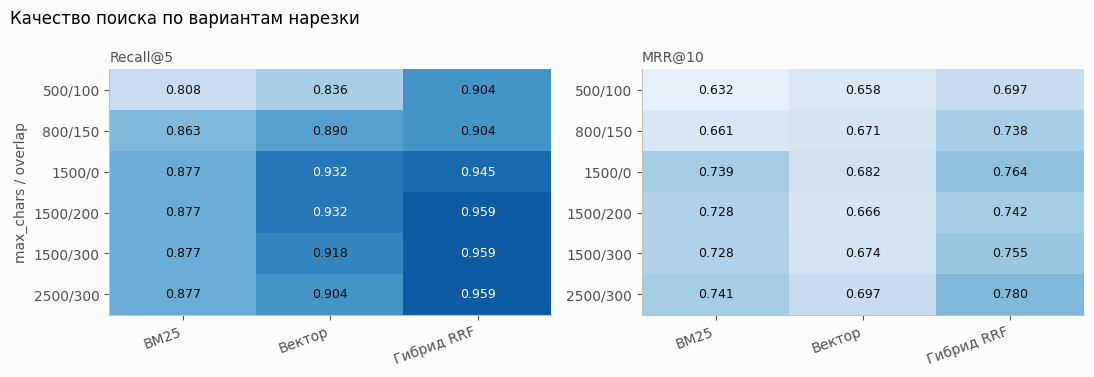

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
fig.suptitle("Качество поиска по вариантам нарезки", x=0.01, ha="left", fontsize=12)
for ax, metric, vmin in zip(axes, ["Recall@5", "MRR@10"], [0.75, 0.6]):
    heatmap(ax, by_chunking[metric].unstack("метод").reindex(variant_order), vmin, "{:.3f}")
    ax.set_title(metric, loc="left", fontsize=10, color="#52514e")
axes[0].set_ylabel("max_chars / overlap")
plt.tight_layout()

**Вывод.** На тепловой карте видно, что мелкие чанки проигрывают всем методам. При нарезке 500 / 100 гибрид RRF находит ответ в первых пяти для 90% вопросов (Recall@5 = 0.904). Причина в том, что короткий чанк часто содержит только половину ответа: например, название показателя в одном чанке, а его значение в соседнем.

Начиная с 1500 символов Recall@5 у BM25 и гибрида перестаёт расти. Крупная нарезка 2500 / 300 даёт гибриду лучший MRR@10 (0.780), но у векторного поиска Recall@5 падает с 0.932 до 0.904: e5 принимает не больше 512 токенов, и конец длинного чанка просто не учитывается. Кроме того, длинные чанки потом труднее передавать в LLM.

Перекрытие при длине 1500 влияет слабо: без перекрытия у гибрида выше MRR@10 (0.764 против 0.742), с перекрытием на один вопрос выше Recall@5 (0.959 против 0.945). Эти различия в пределах одного–двух вопросов. Перекрытие 200 символов оставлено как запас, чтобы фраза на границе двух чанков не терялась.

**Выбран первоначальный вариант нарезки 1500 / 200.**

In [6]:
chunks = load_chunks()
expander = AbbreviationExpander(load_glossary(chunks))
bm25 = BM25Retriever(chunks, expander)
dense = dense_retriever(chunks, "e5", expander)
print(f"нарезка {MAX_CHARS}/{OVERLAP_CHARS}: {len(chunks)} чанков")

нарезка 1500/200: 171 чанков


## 2. BM25 и векторный поиск

Прежде чем объединять методы, их нужно сравнить по отдельности. Гибрид имеет смысл, только если методы ошибаются на разных вопросах. Если бы один из них был лучше на всех категориях, достаточно было бы его одного.

In [7]:
base = pd.DataFrame({"BM25": metrics(bm25), "Вектор (e5)": metrics(dense)}).T
base[["Recall@5", "MRR@10"] + list(CATEGORIES.values())]

,Recall@5,MRR@10,факт/число,процедура,таблица,сокращения,перефраз
BM25,0.877,0.728,0.832,0.857,0.759,0.769,0.445
Вектор (e5),0.932,0.666,0.875,0.762,0.615,0.622,0.440


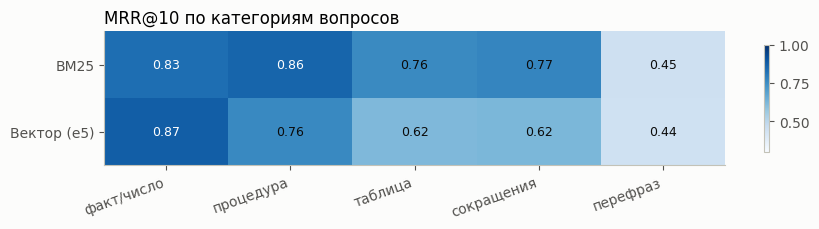

In [8]:
fig, ax = plt.subplots(figsize=(9, 2.4))
image = heatmap(ax, base[list(CATEGORIES.values())], 0.3)
ax.set_title("MRR@10 по категориям вопросов", loc="left", fontsize=12)
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()

**Вывод.** Методы действительно сильны в разном.

По категориям картина такая:

- BM25 заметно лучше на процедурах (0.86 против 0.76), таблицах (0.76 против 0.62) и сокращениях (0.77 против 0.62). В таких вопросах есть точные термины, марки и аббревиатуры, которые дословно встречаются в тексте, а лексический поиск именно на это и рассчитан.
- Векторный поиск немного лучше на фактических вопросах (0.87 против 0.83).
- На перефразированных вопросах оба метода слабые (около 0.45).

Раз методы ошибаются по-разному, их стоит объединить в гибрид.

## 3. Гибрид и вес α

Сравниваются два способа объединить результаты:

- **RRF** (Reciprocal Rank Fusion) учитывает только места чанка в двух выдачах: 1 / (60 + место в BM25) + 1 / (60 + место в векторном поиске).
- **Взвешенная сумма** складывает сами оценки: α · minmax(вектор) + (1 − α) · minmax(BM25). Оценки двух методов приводятся к отрезку [0, 1].

Вес α перебирается от 0 до 1 с шагом 0.1. Пунктиром на графиках показан RRF для сравнения.

In [9]:
alphas = np.round(np.arange(0, 1.01, 0.1), 1)
by_alpha = pd.DataFrame({a: metrics(HybridRetriever(bm25, dense, "weighted", a)) for a in alphas}).T[["Recall@5", "MRR@10"]]
by_alpha.index.name = "α"
rrf = HybridRetriever(bm25, dense, "rrf")
rrf_metrics = metrics(rrf)
by_alpha

,Recall@5,MRR@10
α,,
0.0,0.877,0.728
0.1,0.877,0.730
0.2,0.890,0.739
0.3,0.918,0.743
0.4,0.945,0.760
0.5,0.945,0.775
0.6,0.945,0.777
0.7,0.959,0.771
0.8,0.945,0.755


лучший MRR@10: α = 0.6


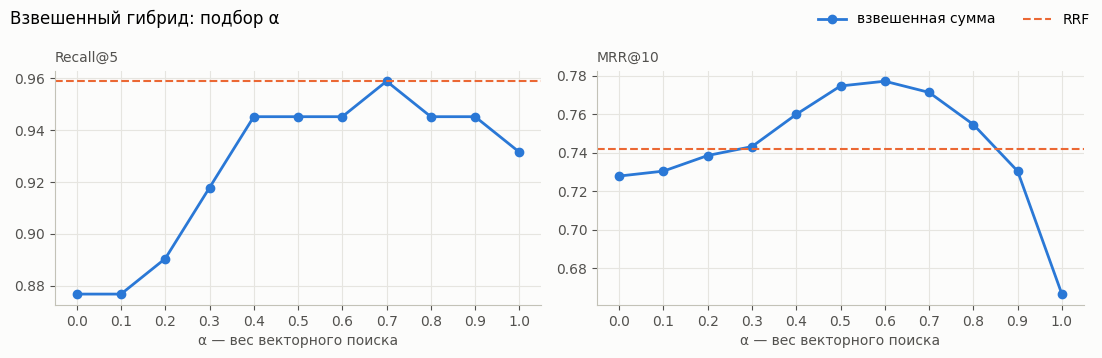

In [10]:
fig, axes = two_panels("Взвешенный гибрид: подбор α")
for ax, metric in zip(axes, ["Recall@5", "MRR@10"]):
    ax.plot(by_alpha.index, by_alpha[metric], color=BLUE, marker="o", label="взвешенная сумма")
    ax.axhline(rrf_metrics[metric], color=ORANGE, linewidth=1.5, linestyle="--", label="RRF")
    ax.set_xlabel("α — вес векторного поиска")
    ax.set_xticks(alphas)
    ax.set_title(metric, loc="left", fontsize=10, color="#52514e")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False)
plt.tight_layout()
print("лучший MRR@10: α =", by_alpha["MRR@10"].idxmax())

**Вывод.** Обе крайние точки графика хуже середины: при α = 0 метрики совпадают с BM25, при α = 1 с векторным поиском. Это ещё раз подтверждает, что вместе методы работают лучше, чем по отдельности.

MRR@10 максимален при α = 0.6 (0.777). Соседние значения 0.5 и 0.7 почти не отличаются (0.775 и 0.771), то есть результат не очень чувствителен к точному выбору α. Recall@5 лучший при α = 0.7 (0.959), но при 0.6 он ниже всего на один вопрос (0.945).

Если сравнивать с RRF, то RRF находит ответ чуть чаще (Recall@5 0.959 против 0.945), а взвешенная сумма ставит его выше (MRR@10 0.777 против 0.742). Однозначно лучшего выбора нет, поэтому дальше проверяются оба гибрида.

In [11]:
weighted = HybridRetriever(bm25, dense, "weighted", DEFAULT_ALPHA)

## 4. Переранжирование

Гибрид отбирает N лучших кандидатов, а кросс-энкодер `mmarco-mMiniLMv2` оценивает каждую пару «вопрос — чанк» целиком и заново сортирует этих кандидатов. В отличие от e5, который кодирует вопрос и чанк отдельно, кросс-энкодер видит их вместе, поэтому точнее, но и гораздо медленнее: время растёт пропорционально N. Для обоих гибридов проверяются N = 5, 10, 20, 30.

In [12]:
depths = [5, 10, 20, 30]
depth_rows = {}
for depth in depths:
    for name, hybrid in [("RRF", rrf), (f"взвеш. α={DEFAULT_ALPHA}", weighted)]:
        m = metrics(reranked(hybrid, depth))
        depth_rows[(depth, name)] = {"Recall@5": m["Recall@5"], "MRR@10": m["MRR@10"]}
by_depth = pd.DataFrame(depth_rows).T
by_depth.index.names = ["кандидатов", "гибрид"]
by_depth.unstack("гибрид")

Recall@5              MRR@10             
гибрид          RRF взвеш. α=0.6    RRF взвеш. α=0.6
кандидатов                                          
5             0.959        0.945  0.840        0.839
10            0.945        0.945  0.847        0.847
20            0.959        0.945  0.839        0.832
30            0.959        0.959  0.838        0.838

лучший MRR@10: (10, 'RRF')


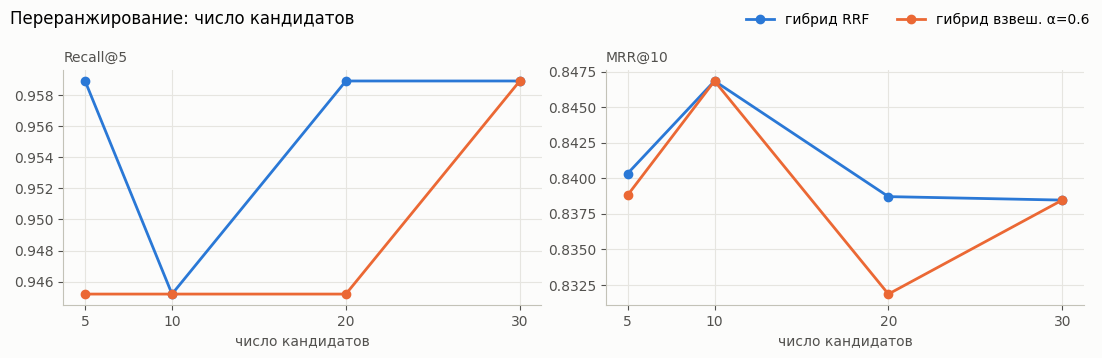

In [13]:
fig, axes = two_panels("Переранжирование: число кандидатов")
for ax, metric in zip(axes, ["Recall@5", "MRR@10"]):
    table = by_depth[metric].unstack("гибрид")
    for column, color in zip(table.columns, [BLUE, ORANGE]):
        ax.plot(table.index, table[column], color=color, marker="o", label=f"гибрид {column}")
    ax.set_xticks(depths)
    ax.set_xlabel("число кандидатов")
    ax.set_title(metric, loc="left", fontsize=10, color="#52514e")
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False)
plt.tight_layout()
print("лучший MRR@10:", by_depth["MRR@10"].idxmax())

Вывод. Само переранжирование даёт большой прирост: у гибрида RRF MRR@10 растёт с 0.742 до 0.84, у взвешенного с 0.777 до 0.83–0.85. От числа кандидатов результат почти не зависит. Уже при 5 кандидатах получается почти весь прирост, лучший MRR@10 у обоих гибридов при 10 кандидатах (0.847), при 20 и 30 он чуть ниже (0.832–0.839). Эта разница соответствует одному–двум вопросам, которые поменялись местами.

Значит, правильный чанк гибрид почти всегда находит в первой пятёрке, но не всегда на первом месте, и кросс-энкодер поднимает его наверх. Дальние кандидаты редко оказываются правильными, а иногда кросс-энкодер ошибочно ставит один из них выше правильного, поэтому при 20–30 кандидатах MRR@10 немного ниже, чем при 10.

Выбрано 20 кандидатов. При 10 кандидатах MRR@10 чуть выше, но у гибрида RRF Recall@5 падает на один вопрос (0.945 вместо 0.959).

20 кандидатов сохраняют лучший Recall@5 у RRF и дают запас на случай, если правильный чанк окажется ниже десятого места.

## 5. Раскрытие аббревиатур

По ТЗ нужно сравнить качество до и после раскрытия аббревиатур и отдельно посмотреть на вопросы третьей категории (С1–С5), где аббревиатуры встречаются чаще всего. При раскрытии к запросу дописывается расшифровка из глоссария (документ 13), например «ДНП» превращается в «ДНП давление насыщенных паров». Предполагалось, что это поможет найти чанки, где термин написан полностью.

In [14]:
final_methods = {
    "BM25": bm25,
    "Вектор (e5)": dense,
    "Гибрид RRF": rrf,
    f"Гибрид взвеш. α={DEFAULT_ALPHA}": weighted,
    "Гибрид RRF + реранкер": reranked(rrf),
    f"Гибрид взвеш. α={DEFAULT_ALPHA} + реранкер": reranked(weighted),
}
plain = {name: metrics(r) for name, r in final_methods.items()}
expanded = {name: metrics(r, expand=True) for name, r in final_methods.items()}
expansion = pd.DataFrame({
    name: {
        "MRR@10 до": plain[name]["MRR@10"], "MRR@10 после": expanded[name]["MRR@10"],
        "С1–С5 Recall@5 до": plain[name]["С1–С5, Recall@5"], "С1–С5 Recall@5 после": expanded[name]["С1–С5, Recall@5"],
    }
    for name in final_methods
}).T
expansion

,MRR@10 до,MRR@10 после,С1–С5 Recall@5 до,С1–С5 Recall@5 после
BM25,0.728,0.644,0.4,0.4
Вектор (e5),0.666,0.692,0.6,0.6
Гибрид RRF,0.742,0.733,0.8,0.8
Гибрид взвеш. α=0.6,0.777,0.730,0.6,0.6
Гибрид RRF + реранкер,0.839,0.816,1.0,1.0
Гибрид взвеш. α=0.6 + реранкер,0.832,0.809,0.8,0.8


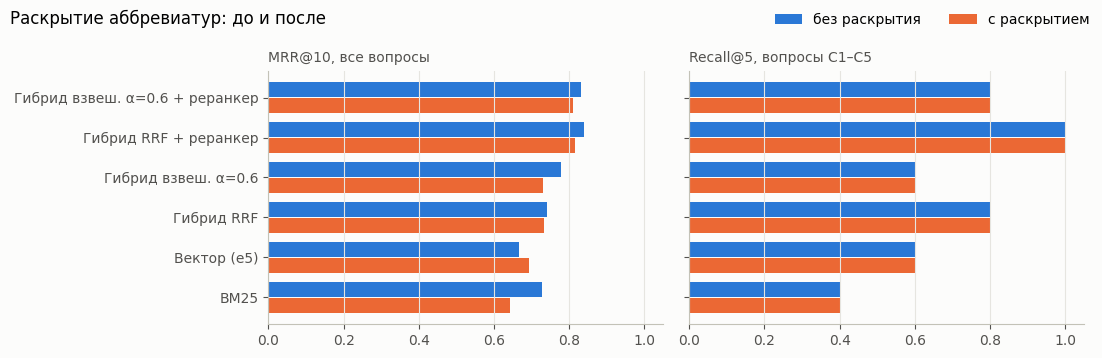

In [15]:
fig, axes = two_panels("Раскрытие аббревиатур: до и после")
y = np.arange(len(expansion))
for ax, (before, after, title) in zip(axes, [
    ("MRR@10 до", "MRR@10 после", "MRR@10, все вопросы"),
    ("С1–С5 Recall@5 до", "С1–С5 Recall@5 после", "Recall@5, вопросы С1–С5"),
]):
    ax.barh(y + 0.2, expansion[before], height=0.38, color=BLUE, label="без раскрытия")
    ax.barh(y - 0.2, expansion[after], height=0.38, color=ORANGE, label="с раскрытием")
    ax.set_yticks(y, expansion.index)
    ax.set_xlim(0, 1.05)
    ax.set_title(title, loc="left", fontsize=10, color="#52514e")
    ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
fig.legend(*axes[0].get_legend_handles_labels(), loc="upper right", ncol=2, frameon=False)
plt.tight_layout()

**Вывод.** Раскрытие аббревиатур не помогает. На левом графике видно, что MRR@10 с раскрытием снижается у всех методов, кроме векторного поиска (там он растёт с 0.666 до 0.692). Сильнее всего падает BM25: с 0.728 до 0.644. На правом графике Recall@5 на вопросах С1–С5 не меняется ни у одного метода.

Скорее всего, дело в том, что в регламенте аббревиатуры обычно и используются в тексте, а полностью термин пишется только в глоссарии и в начале документов. Поэтому расшифровка не добавляет нужных совпадений, а только удлиняет запрос, и BM25 начинает находить чанки, в которых совпадают слова расшифровки, а не то, о чём спрашивали. Векторному поиску расшифровка немного помогает, потому что модель лучше понимает полные слова, чем сокращения, но в гибриде этот выигрыш теряется.

**Поэтому раскрытие по умолчанию выключено.**

## 6. Итоговое сравнение

Здесь все методы собраны вместе с выбранными параметрами: нарезка 1500 / 200, α = 0.6, 20 кандидатов для переранжирования, без раскрытия аббревиатур.

In [16]:
final = pd.DataFrame(plain).T
final[["Recall@5", "MRR@10", "Ловушки"]]

,Recall@5,MRR@10,Ловушки
BM25,0.877,0.728,0.333
Вектор (e5),0.932,0.666,0.000
Гибрид RRF,0.959,0.742,0.333
Гибрид взвеш. α=0.6,0.945,0.777,0.333
Гибрид RRF + реранкер,0.959,0.839,0.000
Гибрид взвеш. α=0.6 + реранкер,0.945,0.832,0.000


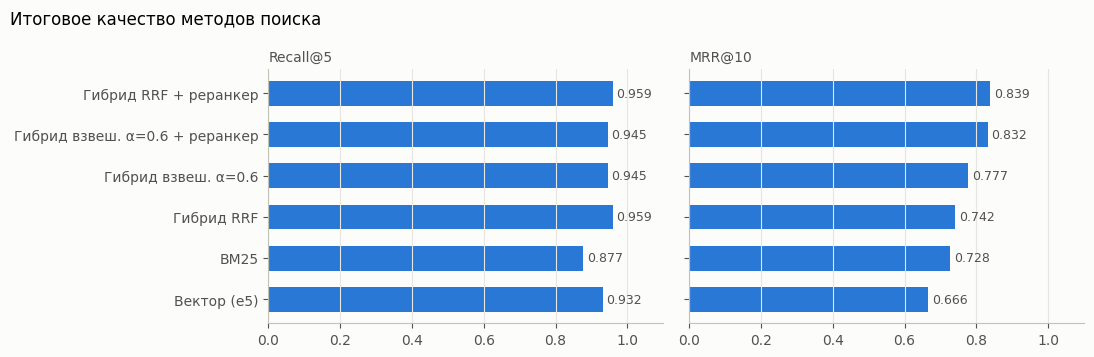

In [17]:
fig, axes = two_panels("Итоговое качество методов поиска")
order = final.sort_values("MRR@10").index
for ax, metric in zip(axes, ["Recall@5", "MRR@10"]):
    values = final.loc[order, metric]
    ax.barh(order, values, color=BLUE, height=0.6)
    for i, v in enumerate(values):
        ax.text(v + 0.01, i, f"{v:.3f}", va="center", color="#52514e", fontsize=9)
    ax.set_xlim(0, 1.1)
    ax.set_title(metric, loc="left", fontsize=10, color="#52514e")
    ax.grid(axis="y", visible=False)
axes[1].set_yticklabels([])
plt.tight_layout()

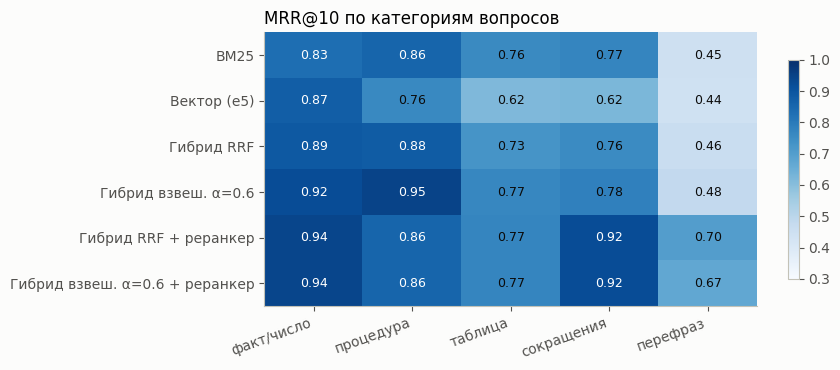

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.8))
image = heatmap(ax, final[list(CATEGORIES.values())], 0.3)
ax.set_title("MRR@10 по категориям вопросов", loc="left", fontsize=12)
fig.colorbar(image, ax=ax, shrink=0.8)
plt.tight_layout()

**Вывод.** Лучший результат у гибрида RRF с переранжированием: Recall@5 = 0.959 (ответ в первой пятёрке у 70 вопросов из 73) и MRR@10 = 0.839. Он же единственный находит все вопросы С1–С5. Взвешенный гибрид с переранжированием почти не отстаёт (0.945 и 0.832).

По тепловой карте видно, где помогает кросс-энкодер. Сильнее всего растут перефразированные вопросы (у RRF с 0.46 до 0.70) и сокращения (с 0.76 до 0.92): именно там совпадения отдельных слов не хватает, и нужно понимать вопрос целиком. На процедурах переранжирование, наоборот, немного мешает: лучший результат там у взвешенного гибрида без реранкера (0.95 против 0.86).

Ловушки по оценке поиска отсечь не получается. У BM25 и гибридов без реранкера порогом отсекается только одна ловушка из трёх, у векторного поиска и у вариантов с реранкером ни одной: поиск всегда находит что-то похожее на вопрос, и оценка у этого чанка не ниже, чем у настоящих ответов. Значит, распознавать вопросы без ответа нужно на следующем этапе, при генерации, когда LLM проверяет, есть ли ответ в найденных чанках.
